# Fase 1: Planteamiento y adquisición de imágenes
## Segmentación por color de productos de supermercado: caso Colgate

**Integrantes:**
- Kevin Mendez
- Christian Naula

**Contenido:**
1. Planteamiento del problema
2. Dataset propio
3. Representación de la imagen y espacios de color
4. Conclusiones

## 1. Planteamiento del problema

**Contexto.** En un supermercado, el personal revisa a mano si los productos están en su estante. Esto es lento y los faltantes pueden pasar desapercibidos. Queremos reconocer productos en fotos de estantes tomadas con celular. El primer paso es **separar el producto del fondo usando su color**; como caso de estudio usamos el logo rojo de **Colgate**.

**Actores:** personal de reposición (toma las fotos), administrador de la tienda (usa los reportes) y equipo de desarrollo (construye el sistema).

**Requisitos funcionales**
- RF1 (prioridad alta): segmentar la región del producto por su color.
- RF2 (prioridad media): identificar la clase del producto.
- RF3 (prioridad media): reportar si el producto está presente en la foto.

**Requisitos no funcionales**
- RNF1 (prioridad alta): funcionar con buena y con poca iluminación.
- RNF2: aceptar fotos de distintos celulares y resoluciones.
- RNF3: procesar cada foto en menos de 1 segundo sin GPU.

La segmentación y la robustez a la luz tienen prioridad alta porque, si fallan, fallan todos los pasos siguientes.

**Restricciones:** luz artificial desigual entre pasillos, sombras y reflejos; cámaras de celular con resoluciones distintas; productos parecidos uno junto al otro y oclusiones (manos, etiquetas).

**Métricas de éxito**

| Métrica | Objetivo |
|---|---|
| La misma regla de color detecta el logo con luz y con sombra | Sí, en ambas fotos |
| IoU entre la máscara y una máscara hecha a mano | ≥ 0,7 |
| Tiempo por foto | < 1 s |

### Librerías

In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import glob

In [2]:
# Librerías para analizar el dataset
from collections import Counter
from pathlib import Path

import pandas as pd
from PIL import Image

## 2. Dataset propio

Tenemos fotos de 10 productos (Antoni, Café, Coca-Cola, Colgate, KitKat, Manzana, Real, Splendor, Té Negro y Zeus), cada uno en su carpeta dentro de `data/raw/`.

**Condiciones de captura:** fotos tomadas con los celulares de los integrantes, en pasillos y estantes de supermercado, con luz artificial (zonas bien iluminadas y zonas en sombra), desde distintos ángulos y distancias.

**Limpieza:** solo se usan archivos `.jpg`; la carpeta `segmentacion_colgate` no se cuenta como clase porque guarda recortes para el análisis de color; no se eliminan fotos oscuras o en ángulo porque representan condiciones reales.

Imágenes: 550 | Clases: 10


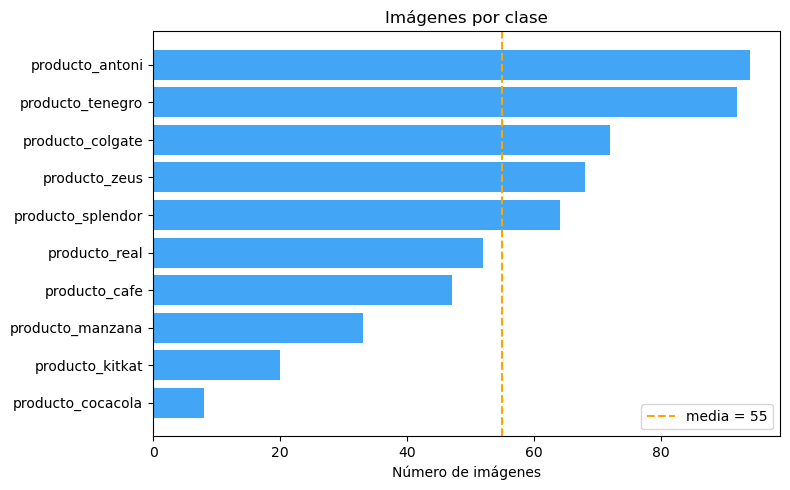

Mínimo: 8 (producto_cocacola) | Máximo: 94 (producto_antoni) | Razón máx/mín: 11.8x


In [3]:
PROPIO = Path("../data/raw")

filas = []
for carpeta in sorted(PROPIO.iterdir()):
    # Solo carpetas de clases (producto_*)
    if not carpeta.is_dir() or not carpeta.name.lower().startswith("producto_"):
        continue
    for archivo in sorted(carpeta.iterdir()):
        if archivo.suffix.lower() == ".jpg":
            filas.append({"clase": carpeta.name, "ruta": archivo})
propio = pd.DataFrame(filas)

conteo = propio["clase"].value_counts().sort_values()
print("Imágenes:", len(propio), "| Clases:", propio["clase"].nunique())
plt.figure(figsize=(8, 5))
plt.barh(conteo.index, conteo.values, color="#42A5F5")
plt.axvline(conteo.mean(), color="orange", ls="--", label=f"media = {conteo.mean():.0f}")
plt.title("Imágenes por clase")
plt.xlabel("Número de imágenes")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Mínimo: {conteo.min()} ({conteo.idxmin()}) | Máximo: {conteo.max()} ({conteo.idxmax()}) "
      f"| Razón máx/mín: {conteo.max() / conteo.min():.1f}x")

> **Observación.** El dataset está desbalanceado: algunas clases tienen bastantes más fotos que otras. Habrá que tenerlo en cuenta al entrenar y evaluar un modelo.

Archivos dañados: 0
Resoluciones más frecuentes (ancho x alto):
  1872 x 4096: 416 imágenes
  3024 x 4032: 56 imágenes
  4032 x 3024: 29 imágenes
  1080 x 2360: 21 imágenes
  4284 x 5712: 17 imágenes
  5712 x 4284: 7 imágenes


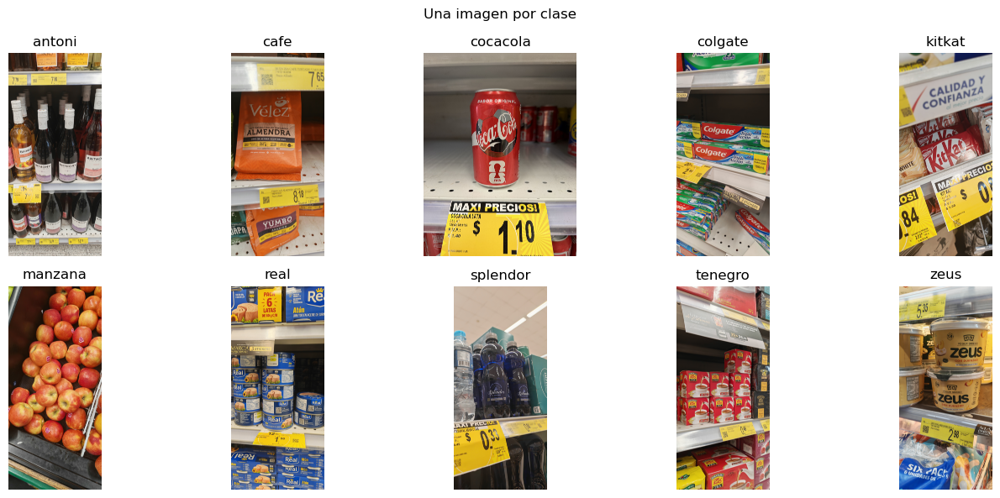

In [4]:
# Resolución de cada foto y verificación de que todas se puedan abrir
tamanos, danadas = [], []
for ruta in propio["ruta"]:
    try:
        with Image.open(ruta) as im:
            tamanos.append(im.size)  # (ancho, alto)
    except Exception:
        danadas.append(ruta)
print("Archivos dañados:", len(danadas))
print("Resoluciones más frecuentes (ancho x alto):")
for (w, h), n in Counter(tamanos).most_common(6):
    print(f"  {w} x {h}: {n} imágenes")

ejemplos = propio.groupby("clase").first()
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, (clase, fila) in zip(axes.ravel(), ejemplos.iterrows()):
    ax.imshow(cv.cvtColor(cv.imread(str(fila["ruta"])), cv.COLOR_BGR2RGB))
    ax.set_title(clase.replace("producto_", ""))
    ax.axis("off")
plt.suptitle("Una imagen por clase")
plt.tight_layout()
plt.show()

> **Observación.** No hay archivos dañados. Las fotos tienen resoluciones altas y distintas entre sí porque vienen de varios celulares, así que más adelante habrá que unificar su tamaño. Los ejemplos muestran la variedad real de la captura: productos en el estante, en la mano, de cerca y de lejos.

## 3. Representación de la imagen y espacios de color

Funciones auxiliares: `mostrar_dos_imagenes` muestra la foto con luz junto a la foto oscura, y `mostrar_canales` separa una imagen en sus tres canales y los muestra en gris.

In [5]:
#metodo para mostrar brillo y oscuro
def mostrar_dos_imagenes(brillo, oscuro, titulos=("Brillo", "Oscuro")):
    imagenes = [brillo, oscuro]
    fig, axes = plt.subplots(1,2, figsize=(10,12))
    for(ax, img, titulo) in zip(axes, imagenes, titulos):
        ax.imshow(img)
        ax.set_title(titulo)
        ax.axis('off')
        plt.tight_layout()
    plt.show()

In [6]:
#metodo para mostrar canales greyscale
def mostrar_canales(img, titulos=("Canal 1", "Canal 2", "Canal 3")):
    A,B,C = cv.split(img)
    canales = [A,B,C]

    fig, axes = plt.subplots(1,3,figsize=(5,6))
    for(ax, img, titulo) in zip(axes, canales, titulos):
        ax.imshow(img, cmap = 'gray')
        ax.set_title(titulo)
        ax.axis('off')
        plt.tight_layout()
    plt.show()
   

Usamos dos fotos de Colgate con iluminación distinta: `colgate5` (pasillo con buena luz) y `colgate60` (estante con poca luz). OpenCV lee en BGR, así que las convertimos a RGB para mostrarlas.

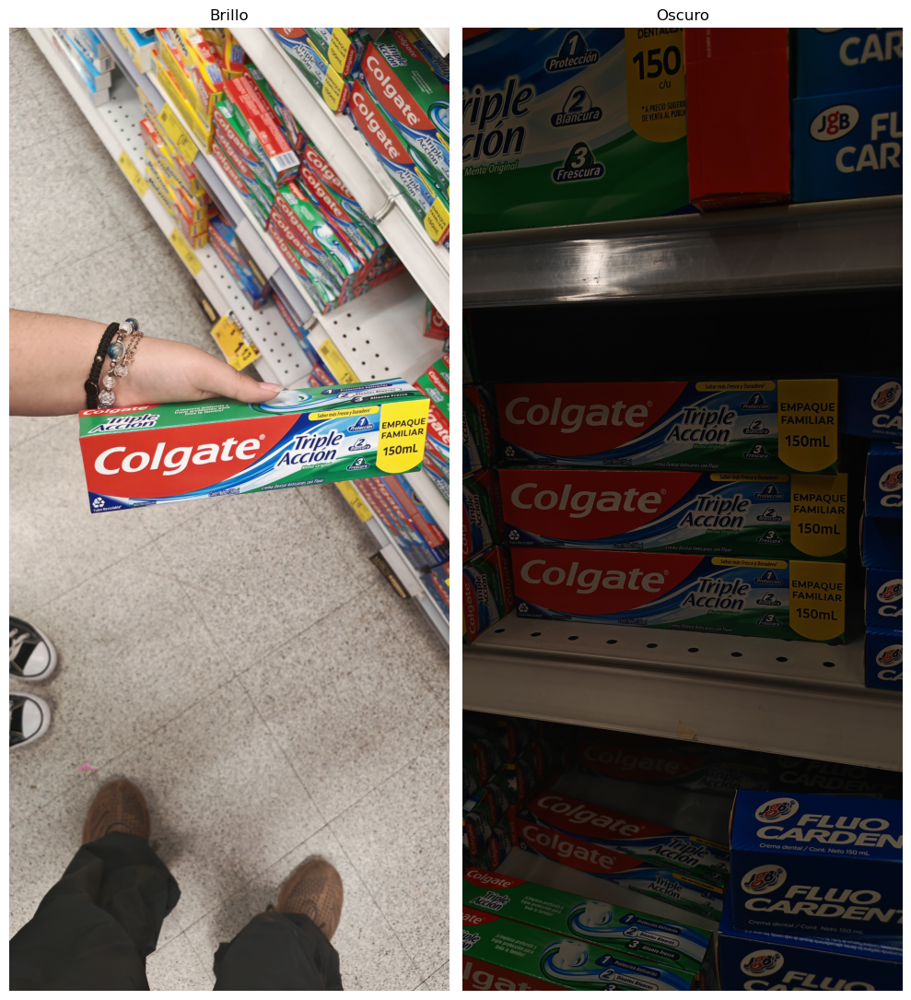

In [7]:
bright = cv.imread('../data/raw/producto_colgate/colgate5.jpg')
dark = cv.imread('../data/raw/producto_colgate/colgate60.jpg')
bright_RGB = cv.cvtColor(bright, cv.COLOR_BGR2RGB)
dark_RGB = cv.cvtColor(dark,cv.COLOR_BGR2RGB)
mostrar_dos_imagenes(bright_RGB, dark_RGB)

> **Observación.** En la foto oscura el rojo del logo se ve apagado aunque es el mismo producto. Una regla de color tiene que funcionar en ambos casos.

### 3.1 Resolución y profundidad de color

In [8]:
for nombre, img in [("Brillo (colgate5)", bright), ("Oscuro (colgate60)", dark)]:
    alto, ancho, canales = img.shape
    bits = img.itemsize * 8
    print(f"{nombre}: {ancho} x {alto} px, {canales} canales, tipo {img.dtype} "
          f"({bits} bits por canal, {bits * canales} bits por píxel), memoria: {img.nbytes / 1e6:.1f} MB")

Brillo (colgate5): 1872 x 4096 px, 3 canales, tipo uint8 (8 bits por canal, 24 bits por píxel), memoria: 23.0 MB
Oscuro (colgate60): 1872 x 4096 px, 3 canales, tipo uint8 (8 bits por canal, 24 bits por píxel), memoria: 23.0 MB


> **Observación.** Cada foto tiene millones de píxeles, con 8 bits por canal (valores de 0 a 255), lo que da más de 16 millones de colores posibles.

### 3.2 Canales RGB

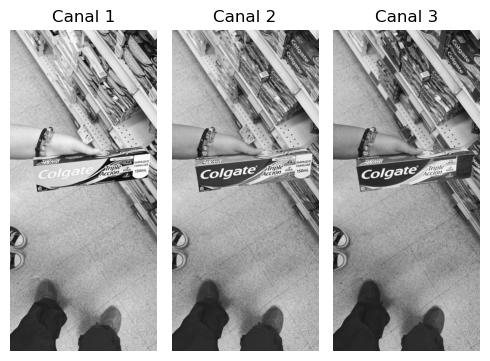

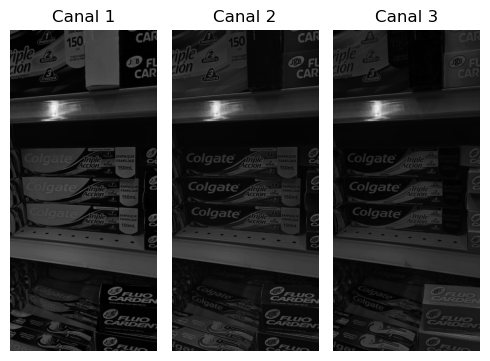

In [9]:
mostrar_canales(bright_RGB)
mostrar_canales(dark_RGB)

> **Observación.** El logo es claro en el canal R y oscuro en G y B, como corresponde al rojo. En la foto oscura los tres canales bajan a la vez: en RGB el color y el brillo están mezclados.

### 3.3 Histogramas por canal

El histograma cuenta cuántos píxeles hay de cada intensidad (0 a 255) en cada canal.

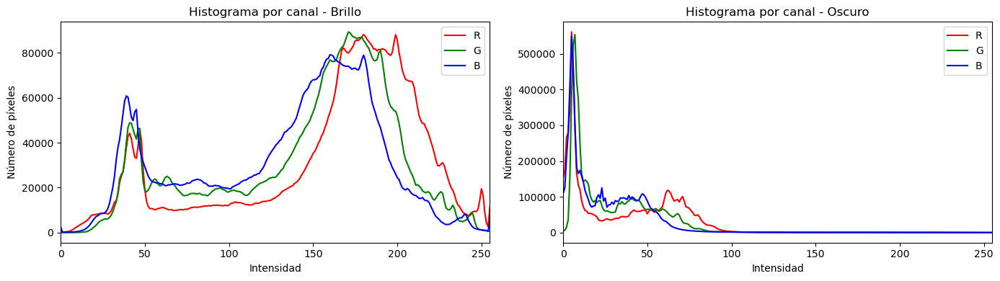

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (nombre, img) in zip(axes, [("Brillo", bright_RGB), ("Oscuro", dark_RGB)]):
    for i, color in enumerate(["red", "green", "blue"]):
        hist = cv.calcHist([img], [i], None, [256], [0, 256]).ravel()
        ax.plot(hist, color=color, label="RGB"[i])
    ax.set_title(f"Histograma por canal - {nombre}")
    ax.set_xlabel("Intensidad")
    ax.set_ylabel("Número de píxeles")
    ax.set_xlim(0, 255)
    ax.legend()
plt.tight_layout()
plt.show()

> **Observación.** Con luz, los canales ocupan casi todo el rango. Con poca luz, los tres histogramas se amontonan en valores bajos. La diferencia entre las fotos es sobre todo de brillo, y en RGB afecta a los tres canales.

### 3.4 Escala de grises y blanco y negro

La escala de grises combina los tres canales en uno ($0.299R + 0.587G + 0.114B$). La imagen en blanco y negro se obtiene con un umbral automático (Otsu).

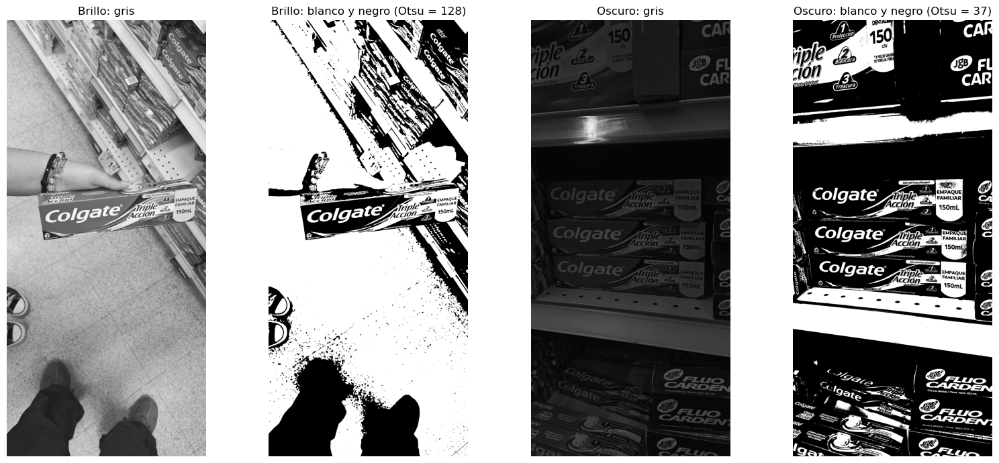

In [11]:
imagenes, titulos = [], []
for nombre, img in [("Brillo", bright), ("Oscuro", dark)]:
    gris = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    umbral, binaria = cv.threshold(gris, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    imagenes += [gris, binaria]
    titulos += [f"{nombre}: gris", f"{nombre}: blanco y negro (Otsu = {umbral:.0f})"]

fig, axes = plt.subplots(1, 4, figsize=(16, 7))
for ax, img, titulo in zip(axes, imagenes, titulos):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
plt.show()

> **Observación.** En gris se conservan las formas, pero el rojo del logo queda como un gris medio parecido a otros objetos. El blanco y negro separa zonas claras de oscuras, no el producto del fondo. Ninguno sirve para segmentar por color.

### 3.5 Espacios LAB, YCrCb y HSV

Estos espacios separan el brillo del color: **LAB** (L* = luminosidad; a*, b* = color), **YCrCb** (Y = luminancia; Cr, Cb = color) y **HSV** (H = matiz, S = saturación, V = brillo).

> Al mostrar estas imágenes completas aparecen colores falsos, porque Matplotlib interpreta sus canales como RGB. Lo útil es mirar cada canal por separado.

**LAB**

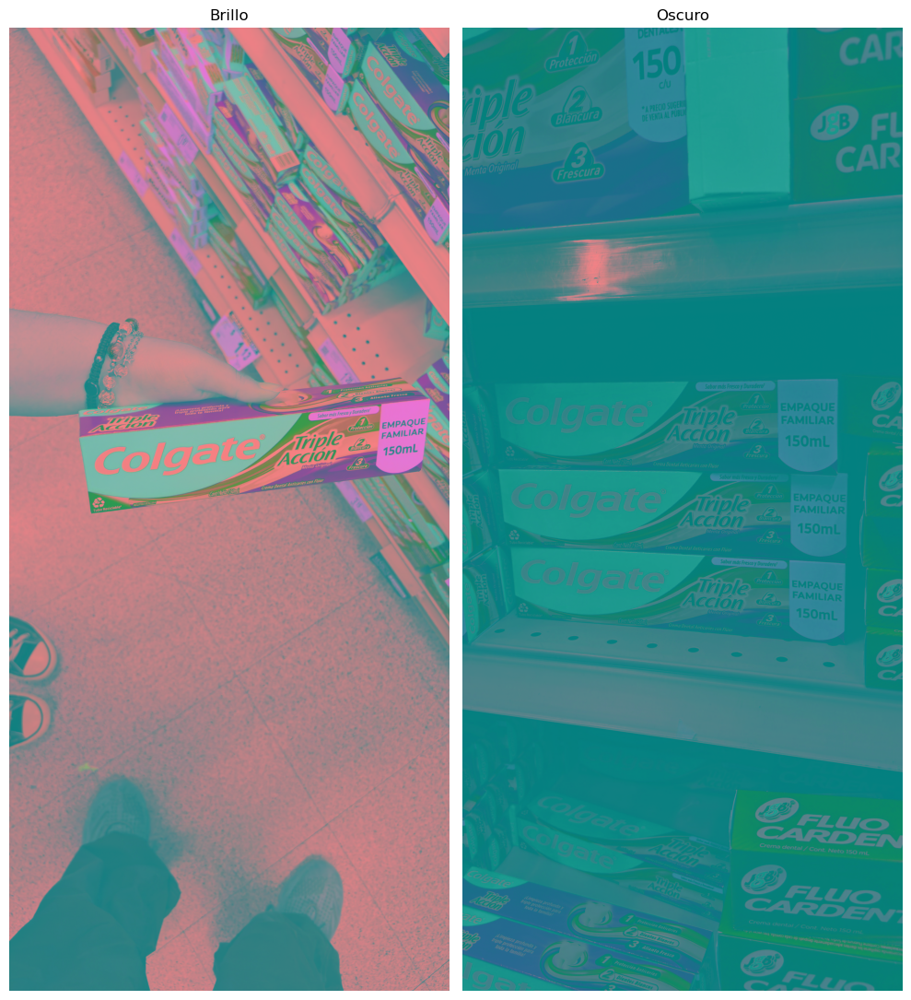

In [12]:
brightLAB = cv.cvtColor(bright, cv.COLOR_BGR2LAB)
darkLAB = cv.cvtColor(dark, cv.COLOR_BGR2LAB)
mostrar_dos_imagenes(brightLAB, darkLAB)

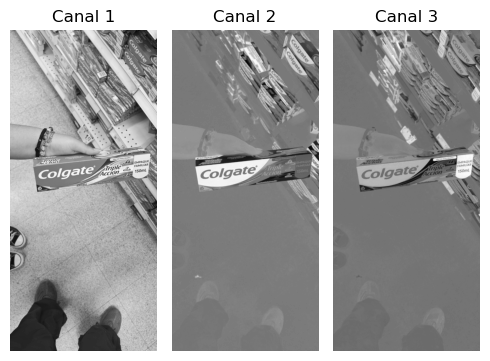

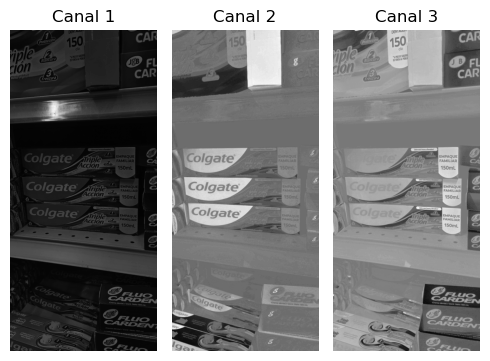

In [13]:
mostrar_canales(brightLAB)
mostrar_canales(darkLAB)

> **Observación.** L* concentra el cambio de luz entre las dos fotos, mientras que en a* (verde-rojo) el logo se ve claro en ambas.

**YCrCb**

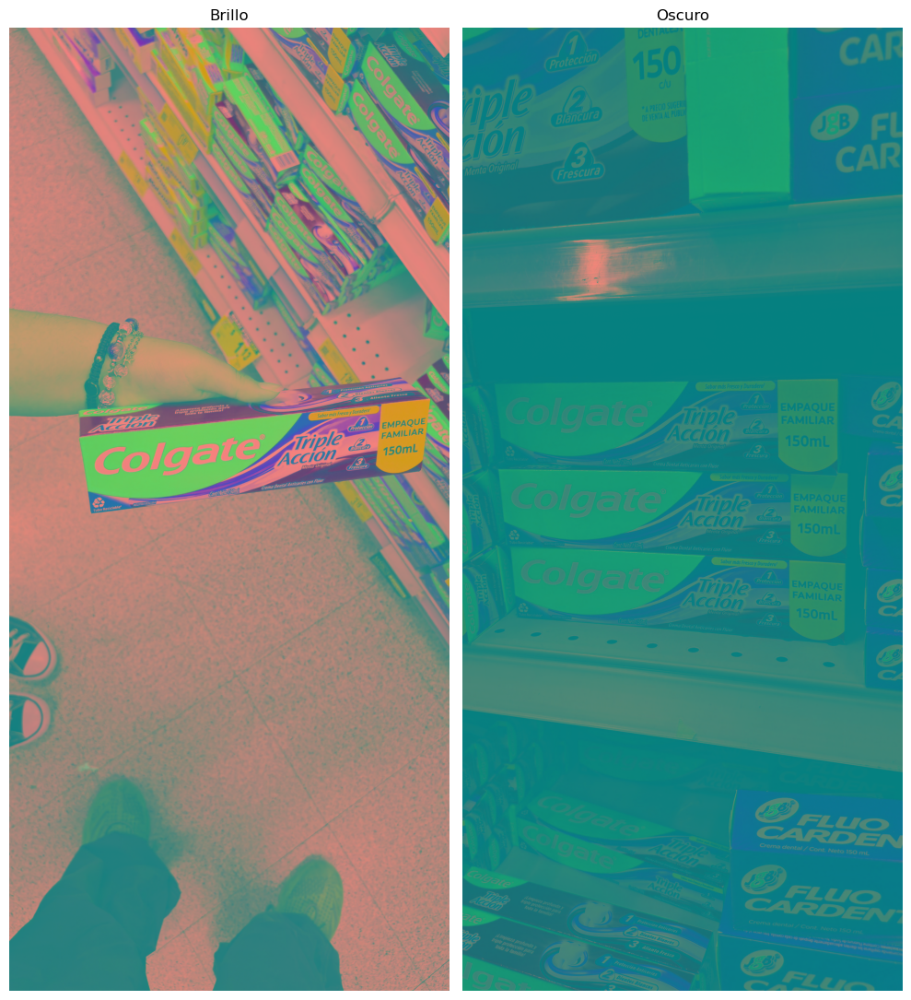

In [14]:
brightYCB = cv.cvtColor(bright, cv.COLOR_BGR2YCrCb)
darkYCB = cv.cvtColor(dark, cv.COLOR_BGR2YCrCb)
mostrar_dos_imagenes(brightYCB,darkYCB)

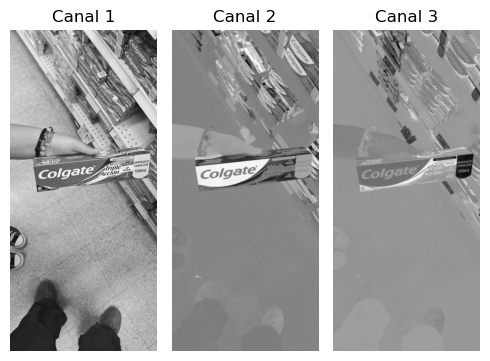

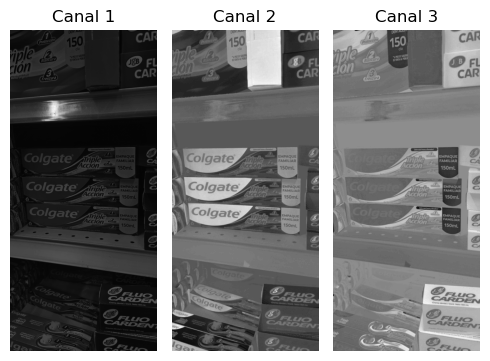

In [15]:
mostrar_canales(brightYCB)
mostrar_canales(darkYCB)

> **Observación.** Igual que en LAB: Y lleva el brillo y Cr resalta el rojo del logo en las dos fotos.

**HSV**

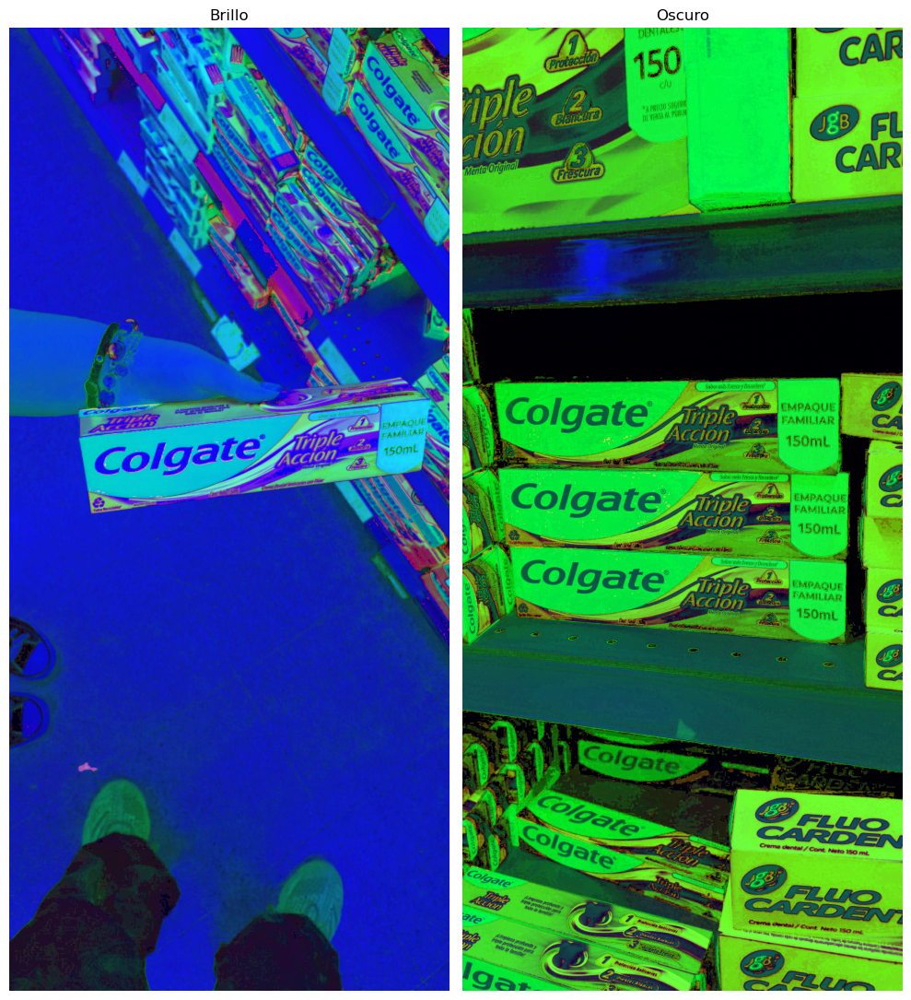

In [16]:
brightHSV = cv.cvtColor(bright, cv.COLOR_BGR2HSV)
darkHSV = cv.cvtColor(dark, cv.COLOR_BGR2HSV)
mostrar_dos_imagenes(brightHSV,darkHSV)

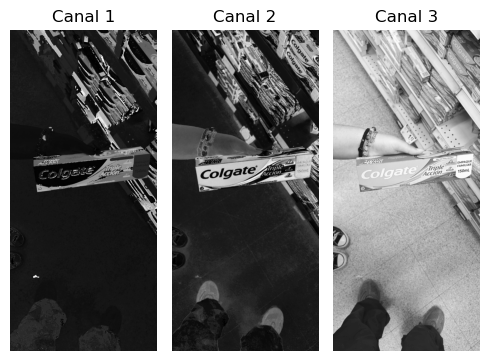

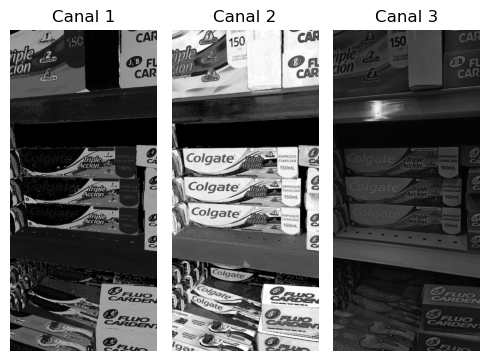

In [17]:
mostrar_canales(brightHSV)
mostrar_canales(darkHSV)

> **Observación.** El logo tiene H cercano a 0 (rojo) y S alta en las dos fotos; el cambio de luz se concentra en V.

### 3.6 Segmentación en BGR

Con `cv.inRange` creamos una máscara que marca en blanco los píxeles cercanos al rojo del logo: BGR = (45, 55, 195) ± 45.

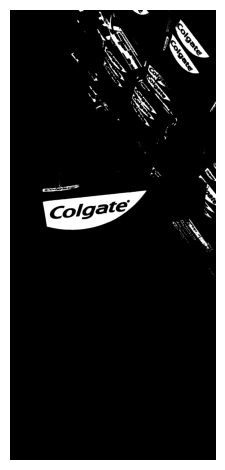

In [18]:
bgr = [45, 55, 195]
thresh = 45

minBGR = np.array([bgr[0] - thresh, bgr[1] - thresh, bgr[2] - thresh])
maxBGR = np.array([bgr[0] + thresh, bgr[1] + thresh, bgr[2] + thresh])

maskBGR = cv.inRange(bright,minBGR,maxBGR)
resultBGR = cv.bitwise_and(bright, bright, mask = maskBGR)
#resultRGB = cv.bitwise_and(bright,bright,mask=maskRGB)

plt.axis('off')
plt.imshow(maskBGR, cmap='gray')
plt.axis('off')
plt.tight_layout()
plt.show()


> **Observación.** En la foto con luz la máscara encuentra el logo, junto con partes de otros empaques rojos del fondo.

### 3.7 Histogramas 2D de los recortes

Usamos los recortes de `segmentacion_colgate`: `sample_big` (escena con el producto) y `sample_small` (solo el logo). Un histograma 2D cuenta los píxeles por cada combinación de dos canales; si el logo forma una nube compacta, es fácil separarlo en ese espacio.

In [19]:
image_paths = glob.glob("../data/raw/segmentacion_colgate/sample_big/*.jpg")
print(image_paths)

image_paths2 = glob.glob("../data/raw/segmentacion_colgate/sample_small/*.jpg")
print(image_paths2)

['../data/raw/segmentacion_colgate/sample_big\\sample_big1.jpg', '../data/raw/segmentacion_colgate/sample_big\\sample_big2.jpg', '../data/raw/segmentacion_colgate/sample_big\\sample_big3.jpg', '../data/raw/segmentacion_colgate/sample_big\\sample_big4.jpg']
['../data/raw/segmentacion_colgate/sample_small\\sample_small1.jpg', '../data/raw/segmentacion_colgate/sample_small\\sample_small2.jpg', '../data/raw/segmentacion_colgate/sample_small\\sample_small3.jpg', '../data/raw/segmentacion_colgate/sample_small\\sample_small4.jpg']


(0.0, 255.0)

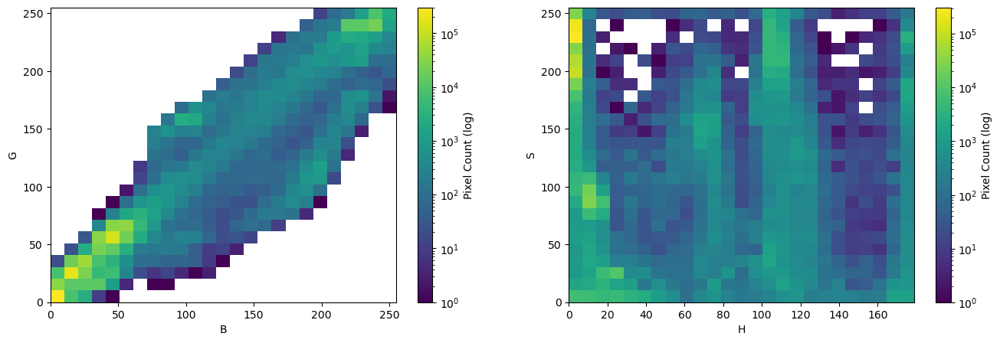

In [20]:
B = np.array([])
G = np.array([])
R = np.array([])

H = np.array([])
S = np.array([])
V = np.array([])

for fi in  image_paths: 
    mimami = cv.imread(fi)
    im2 = cv.cvtColor(mimami, cv.COLOR_BGR2HSV)
    #esto para Rgb
    b = mimami[:,:,0]
    b = b.reshape(b.shape[0]*b.shape[1])
    g = mimami[:,:,1]
    g = g.reshape(g.shape[0]*g.shape[1])
    r = mimami[:,:,2]
    r = r.reshape(r.shape[0]*r.shape[1])
    B = np.append(B,b)
    G = np.append(G,g)
    R = np.append(R,r)
    #esto para hsv
    h = im2[:,:,0]
    h = h.reshape(h.shape[0]*h.shape[1])
    s = im2[:,:,1]
    s = s.reshape(s.shape[0]*s.shape[1])
    v = im2[:,:,2]
    v = v.reshape(v.shape[0]*v.shape[1])
    H = np.append(H,h)
    S = np.append(S,s)
    V = np.append(V,v)

plt.figure(figsize=(16,5))
nbins = 25
plt.subplot(1,2,1)
plt.hist2d(B, G, bins=nbins, norm=LogNorm())
plt.colorbar(label='Pixel Count (log)')
plt.xlabel('B')
plt.ylabel('G')
plt.xlim([0,255])
plt.ylim([0,255])

plt.subplot(1,2,2)
plt.hist2d(H, S, bins=nbins, norm=LogNorm())
plt.colorbar(label='Pixel Count (log)')
plt.xlabel('H')
plt.ylabel('S')
plt.xlim([0,179])
plt.ylim([0,255])

> **Observación.** En B vs G los puntos forman una diagonal: ambos canales dependen del brillo. En H vs S aparecen grupos por matiz, con el rojo concentrado en H ≈ 0.

La función `analyze_color_space` generaliza este código para comparar todos los pares de canales de cada espacio.

In [21]:
def analyze_color_space(
    image_paths,
    color_code=None,
    names=("Ch 0", "Ch 1", "Ch 2"),
    limits=((0, 255), (0, 255), (0, 255)),
    sample_step=5,
    nbins=25,
):
    ch0_list, ch1_list, ch2_list = [], [], []

    for fi in image_paths:
        img = cv.imread(fi)
        if img is None:
            continue

        
        img = img[::sample_step, ::sample_step]
        if color_code is not None:
            img = cv.cvtColor(img, color_code)

        
        ch0_list.append(img[:, :, 0].ravel())
        ch1_list.append(img[:, :, 1].ravel())
        ch2_list.append(img[:, :, 2].ravel())

    c0 = np.concatenate(ch0_list)
    c1 = np.concatenate(ch1_list)
    c2 = np.concatenate(ch2_list)

    pairs = [
        (c0, c1, names[0], names[1], limits[0], limits[1]),
        (c0, c2, names[0], names[2], limits[0], limits[2]),
        (c1, c2, names[1], names[2], limits[1], limits[2]),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, (x, y, xlabel, ylabel, xlim, ylim) in zip(axes, pairs):
        h = ax.hist2d(x, y, bins=nbins, norm=LogNorm())
        fig.colorbar(h[3], ax=ax, label="Counts (log)")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.set_title(f"{xlabel} vs {ylabel}")

    plt.tight_layout()
    plt.show()

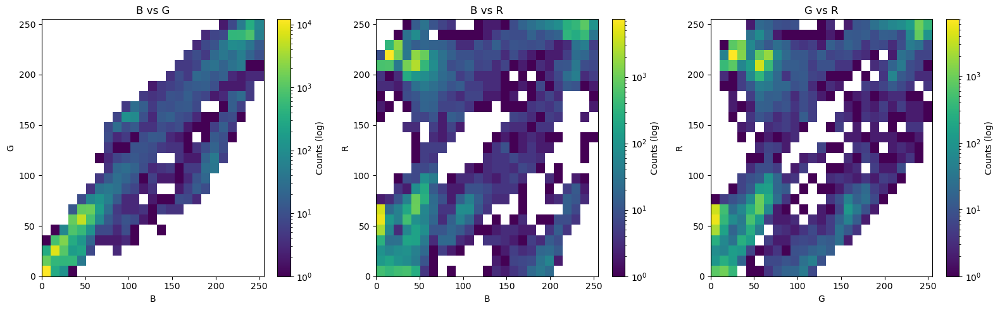

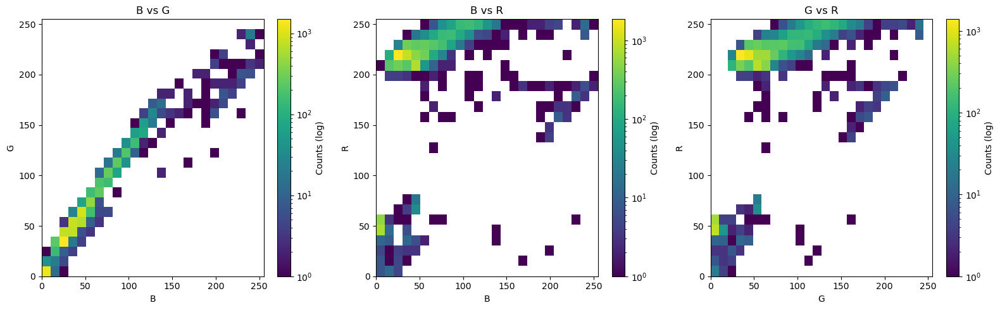

In [22]:
analyze_color_space(
    image_paths,
    color_code=None,  # OpenCV reads BGR directly
    names=("B", "G", "R"),
    limits=((0, 255), (0, 255), (0, 255)),
)
analyze_color_space(
    image_paths2,
    color_code=None,  # OpenCV reads BGR directly
    names=("B", "G", "R"),
    limits=((0, 255), (0, 255), (0, 255)),
)

> **Observación (BGR).** Los canales están correlacionados y el rojo del logo se estira a lo largo de R según la luz.

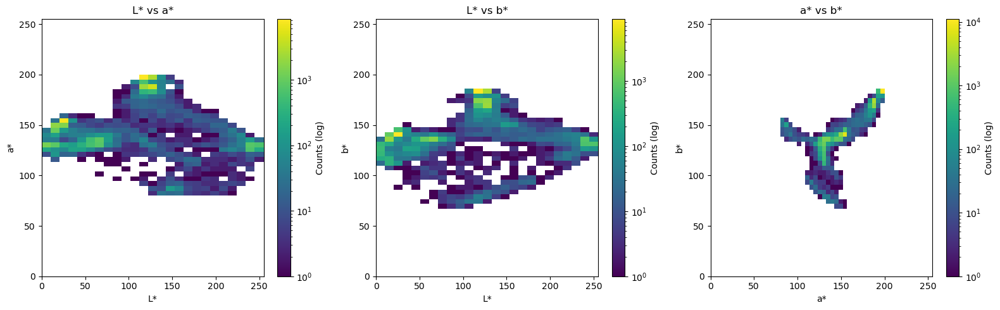

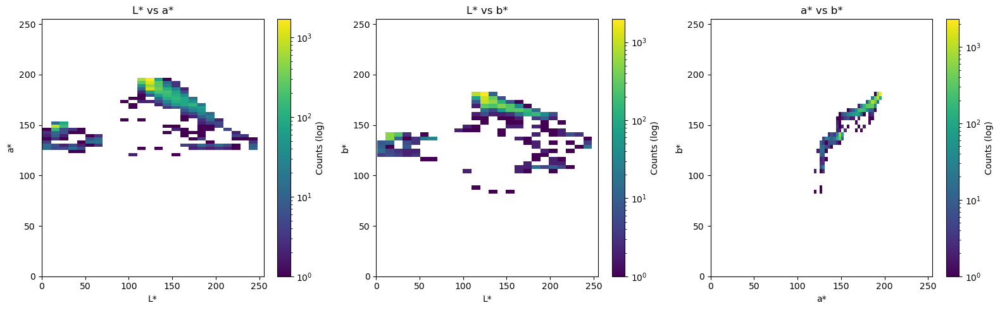

In [23]:
analyze_color_space(
    image_paths,
    color_code=cv.COLOR_BGR2LAB,
    names=("L*", "a*", "b*"),
    limits=((0, 255), (0, 255), (0, 255)),
)
analyze_color_space(
    image_paths2,
    color_code=cv.COLOR_BGR2LAB,
    names=("L*", "a*", "b*"),
    limits=((0, 255), (0, 255), (0, 255)),
)

> **Observación (LAB).** En a* vs b* el logo forma una nube compacta; la luz se reparte en L*.

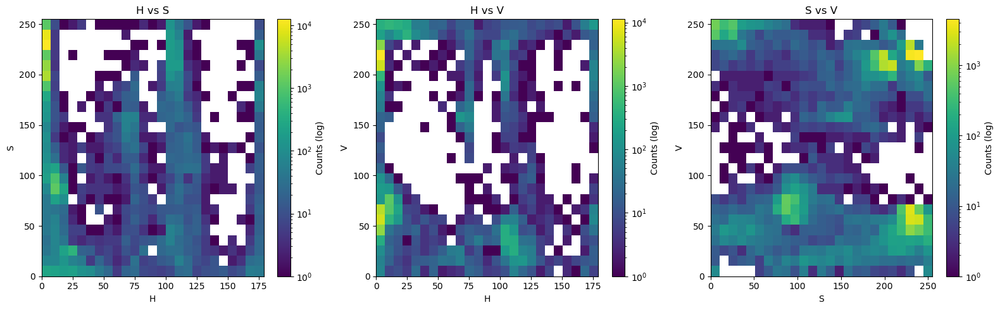

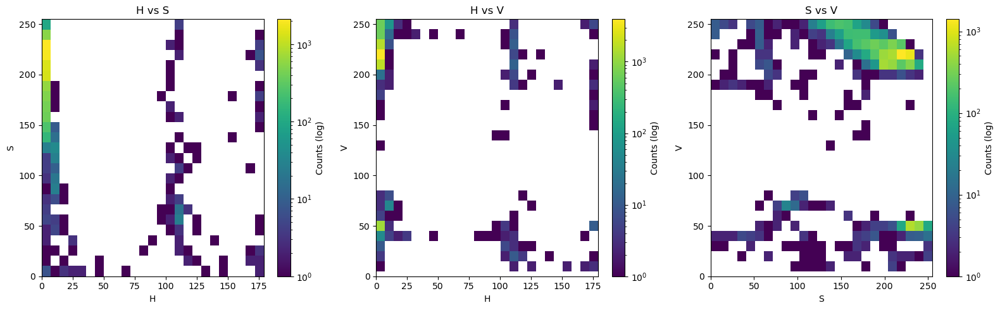

In [24]:
analyze_color_space(
    image_paths,
    color_code=cv.COLOR_BGR2HSV,
    names=("H", "S", "V"),
    limits=((0, 179), (0, 255), (0, 255)),  # H max is 179 in OpenCV
)
analyze_color_space(
    image_paths2,
    color_code=cv.COLOR_BGR2HSV,
    names=("H", "S", "V"),
    limits=((0, 179), (0, 255), (0, 255)),  # H max is 179 in OpenCV
)


> **Observación (HSV).** El logo se concentra en H ≈ 0-10 con S alta, mientras que V varía mucho. El color queda en H y S, y la luz en V.

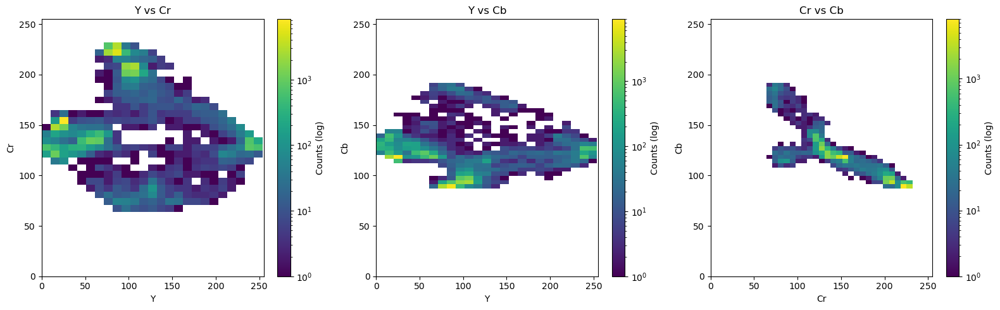

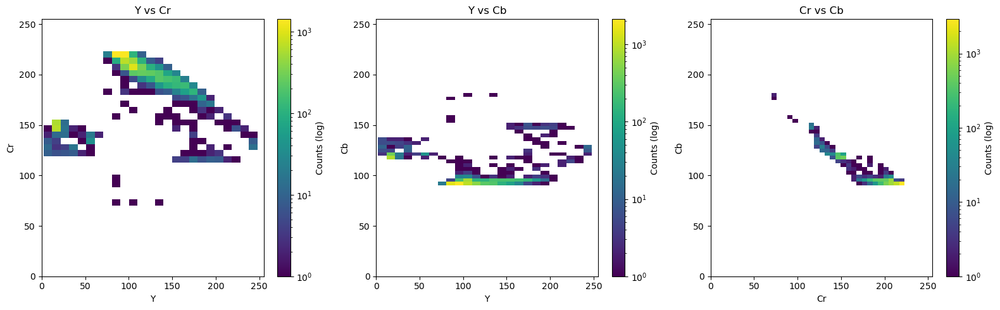

In [25]:
analyze_color_space(
    image_paths,
    color_code=cv.COLOR_BGR2YCrCb,
    names=("Y", "Cr", "Cb"),
    limits=((0, 255), (0, 255), (0, 255)),
)
analyze_color_space(
    image_paths2,
    color_code=cv.COLOR_BGR2YCrCb,
    names=("Y", "Cr", "Cb"),
    limits=((0, 255), (0, 255), (0, 255)),
)

> **Observación (YCrCb).** Cr vs Cb también agrupa el logo. LAB, YCrCb y HSV separan mejor el logo que BGR; elegimos HSV porque sus rangos son fáciles de interpretar y ajustar.

### 3.8 Segmentación en HSV

Centro HSV = (3, 200, 195). Probamos una tolerancia amplia y otra estrecha. A la izquierda se ve la imagen HSV con colores falsos; a la derecha, el resultado en RGB.

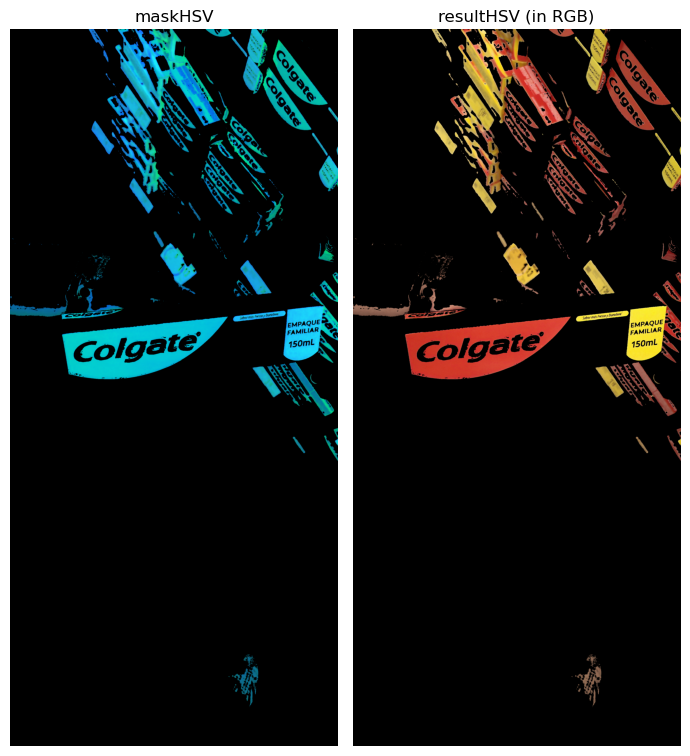

In [26]:
hsv_center = [3, 200, 195]
thresh_hsv = [30, 100, 80] 

minHSV = np.array([
    max(0, hsv_center[0] - thresh_hsv[0]),
    max(0, hsv_center[1] - thresh_hsv[1]),
    max(0, hsv_center[2] - thresh_hsv[2])
])

maxHSV = np.array([
    min(179, hsv_center[0] + thresh_hsv[0]),
    min(255, hsv_center[1] + thresh_hsv[1]),
    min(255, hsv_center[2] + thresh_hsv[2])
])

maskHSV = cv.inRange(brightHSV, minHSV, maxHSV)
resultHSV = cv.bitwise_and(brightHSV, brightHSV, mask=maskHSV)

resultRGB = cv.cvtColor(resultHSV, cv.COLOR_HSV2RGB)

plt.figure(figsize=(7, 8))

plt.subplot(1, 2, 1)
plt.imshow(resultHSV)
plt.title('maskHSV')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(resultRGB)
plt.title('resultHSV (in RGB)')
plt.axis('off')

plt.tight_layout()
plt.show()

> **Observación (tolerancia amplia).** Con H de 0 a 33 también entran amarillos y naranjas, como el recuadro "Empaque familiar".

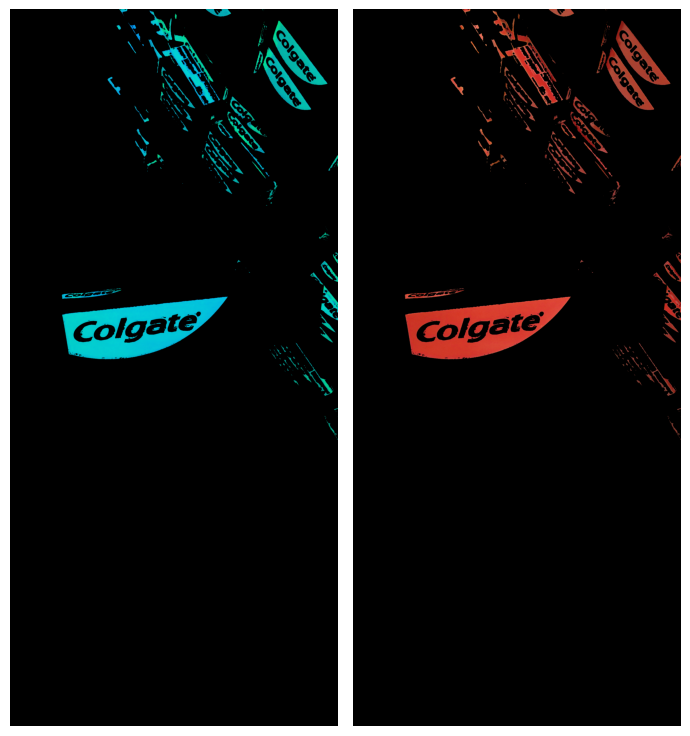

In [27]:
hsv_center = [3, 200, 195]
thresh_hsv = [8, 60, 65]

hsv = np.array(hsv_center)

minHSV = np.array([
    max(0, hsv_center[0] - thresh_hsv[0]),
    max(0, hsv_center[1] - thresh_hsv[1]),
    max(0, hsv_center[2] - thresh_hsv[2])
])

maxHSV = np.array([
    min(179, hsv_center[0] + thresh_hsv[0]),
    min(255, hsv_center[1] + thresh_hsv[1]),
    min(255, hsv_center[2] + thresh_hsv[2])
])

maskHSV = cv.inRange(brightHSV, minHSV, maxHSV)

resultHSV = cv.bitwise_and(brightHSV, brightHSV, mask=maskHSV)
resultRGB = cv.cvtColor(resultHSV, cv.COLOR_HSV2RGB)

plt.figure(figsize=(7, 8))

plt.subplot(1, 2, 1)
plt.imshow(resultHSV)
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(resultRGB)
plt.axis('off')

plt.tight_layout()
plt.show()

> **Observación (tolerancia estrecha).** Con H de 0 a 11 queda casi solo el rojo del logo; la máscara es más limpia que la de BGR.

### 3.9 Robustez a la iluminación

Aplicamos las mismas máscaras a la foto oscura.

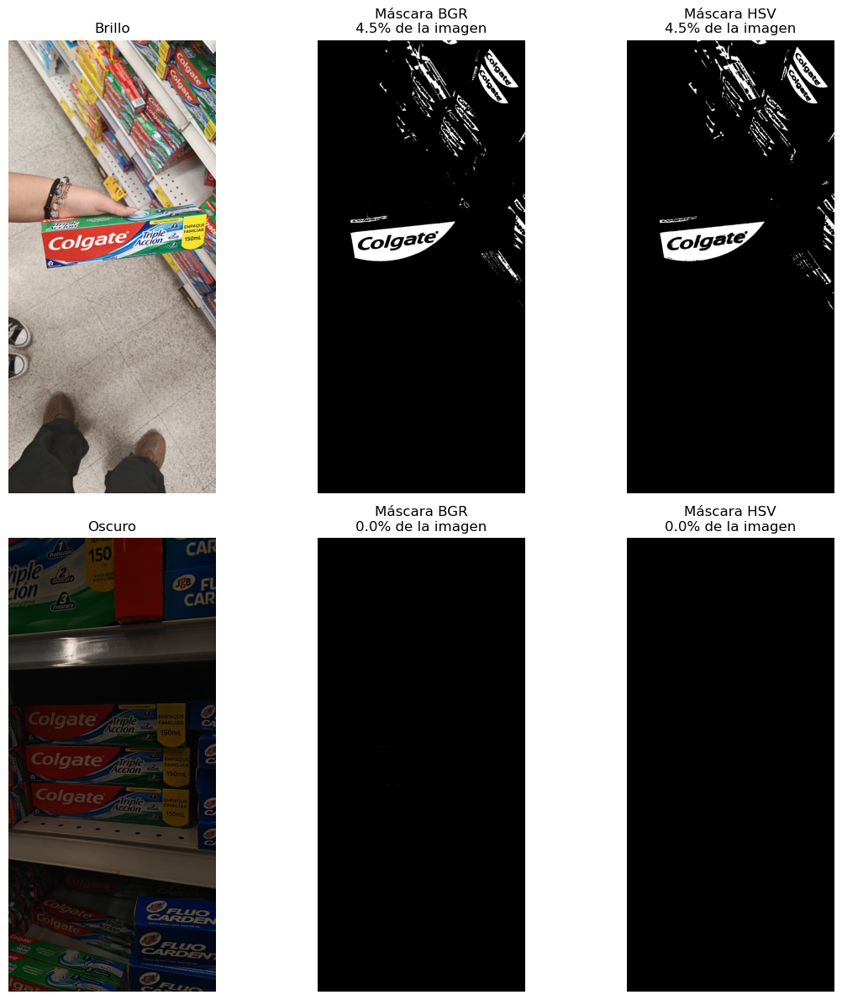

Brillo: V mediano de los píxeles rojos = 203
Oscuro: V mediano de los píxeles rojos = 59


In [28]:
def porcentaje(mascara):
    return f"{(mascara > 0).mean():.1%} de la imagen"


# Las mismas reglas de 3.6 (BGR) y 3.8 (HSV estrecha), ahora también en la foto oscura
maskBGR_oscuro = cv.inRange(dark, minBGR, maxBGR)
maskHSV_oscuro = cv.inRange(darkHSV, minHSV, maxHSV)

fig, axes = plt.subplots(2, 3, figsize=(12, 12))
for fila, (nombre, img, m_bgr, m_hsv) in enumerate([("Brillo", bright_RGB, maskBGR, maskHSV),
                                                    ("Oscuro", dark_RGB, maskBGR_oscuro, maskHSV_oscuro)]):
    axes[fila, 0].imshow(img)
    axes[fila, 0].set_title(nombre)
    axes[fila, 1].imshow(m_bgr, cmap="gray")
    axes[fila, 1].set_title(f"Máscara BGR\n{porcentaje(m_bgr)}")
    axes[fila, 2].imshow(m_hsv, cmap="gray")
    axes[fila, 2].set_title(f"Máscara HSV\n{porcentaje(m_hsv)}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

# Brillo (V) de los píxeles rojos en cada foto
for nombre, hsv in [("Brillo", brightHSV), ("Oscuro", darkHSV)]:
    rojo = (cv.inRange(hsv, (0, 150, 15), (10, 255, 255)) > 0) | (cv.inRange(hsv, (170, 150, 15), (179, 255, 255)) > 0)
    print(f"{nombre}: V mediano de los píxeles rojos = {np.median(hsv[..., 2][rojo]):.0f}")

> **Observación.** En la foto oscura ambas máscaras quedan casi vacías. El rojo del logo tiene ahí un V mucho más bajo, y la regla HSV exigía V ≥ 130 porque se ajustó con la foto clara. Pero H y S siguen siendo los de un rojo intenso, así que en HSV basta con abrir V.

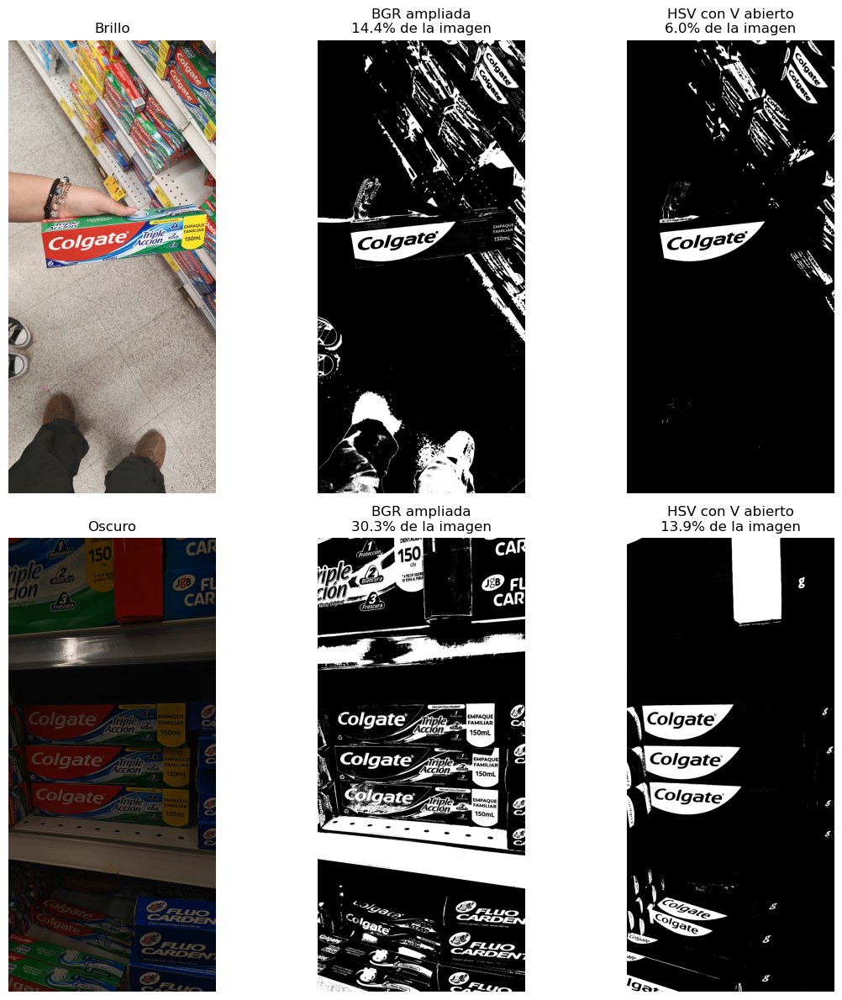

In [29]:
def mascara_rojo_hsv(img_hsv):
    # H y S estrictos (rojo intenso); V abierto de 20 a 255 para tolerar poca luz
    bajo = cv.inRange(img_hsv, (0, 120, 20), (10, 255, 255))
    alto = cv.inRange(img_hsv, (170, 120, 20), (179, 255, 255))
    return cv.bitwise_or(bajo, alto)


def mascara_rojo_bgr_amplia(img_bgr):
    # En BGR, para aceptar el rojo oscuro hay que bajar el mínimo de R hasta 45
    return cv.inRange(img_bgr, (0, 10, 45), (90, 100, 255))


fig, axes = plt.subplots(2, 3, figsize=(12, 12))
for fila, (nombre, img_bgr, img_hsv, img_rgb) in enumerate([("Brillo", bright, brightHSV, bright_RGB),
                                                             ("Oscuro", dark, darkHSV, dark_RGB)]):
    m_bgr, m_hsv = mascara_rojo_bgr_amplia(img_bgr), mascara_rojo_hsv(img_hsv)
    axes[fila, 0].imshow(img_rgb)
    axes[fila, 0].set_title(nombre)
    axes[fila, 1].imshow(m_bgr, cmap="gray")
    axes[fila, 1].set_title(f"BGR ampliada\n{porcentaje(m_bgr)}")
    axes[fila, 2].imshow(m_hsv, cmap="gray")
    axes[fila, 2].set_title(f"HSV con V abierto\n{porcentaje(m_hsv)}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

> **Observación.** La máscara HSV con V abierto detecta los logos en las dos fotos. La máscara BGR ampliada también capta el rojo oscuro, pero deja entrar el piso, el estante y otros empaques. Con HSV, una misma regla funciona con luz y con sombra.

### 3.10 Comparación de espacios de color

| Espacio | ¿Separa color y brillo? | Resultado |
|---|---|---|
| Gris / blanco y negro | No (sin color) | No distingue el logo rojo de otros objetos |
| RGB / BGR | No | Funciona con una sola luz; con poca luz falla o atrapa el fondo |
| LAB / YCrCb | Sí | El logo forma una nube compacta en los canales de color |
| **HSV** | **Sí** | **Una misma regla detecta el logo con luz y con sombra** |

Elegimos **HSV** para segmentar productos por color.

## 4. Conclusiones

- La variación de luz es la principal dificultad para reconocer productos en estantes; por eso la robustez a la iluminación es prioritaria.
- El dataset propio está desbalanceado y tiene resoluciones altas y variadas; habrá que unificar el tamaño de las imágenes.
- Gris y blanco y negro conservan formas pero pierden el color, así que no sirven para segmentar por color.
- En RGB el brillo afecta a los tres canales; LAB, YCrCb y HSV lo separan del color.
- Una regla ajustada con una sola foto falla con otra luz, incluso en HSV. La ventaja de HSV es que permite abrir solo V y mantener H y S, y así detectar el logo en ambas condiciones.
- La segmentación por color también marca otros productos del mismo color; en las siguientes fases habrá que añadir forma, textura y modelos.